In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn statsmodels openpyxl

Note: you may need to restart the kernel to use updated packages.


### Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

import warnings
warnings.filterwarnings("ignore")

### Load the dataset

In [3]:
df = pd.read_csv("HHS_Unaccompanied_Alien_Children_Program.csv")

print("Dataset loaded successfully")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully
Shape: (1170, 6)


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
0,"December 21, 2025",6.0,18.0,11.0,"2,484",14.0
1,"December 18, 2025",11.0,50.0,6.0,"2,472",16.0
2,"December 17, 2025",7.0,31.0,11.0,"2,481",10.0
3,"December 16, 2025",8.0,54.0,15.0,"2,468",9.0
4,"December 15, 2025",11.0,42.0,9.0,"2,470",7.0


### Check dataset information

In [4]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

display(df.describe(include="all"))

Column names:
['Date', 'Children apprehended and placed in CBP custody*', 'Children in CBP custody', 'Children transferred out of CBP custody', 'Children in HHS Care', 'Children discharged from HHS Care']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1170 entries, 0 to 1169
Data columns (total 6 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   Date                                             720 non-null    object 
 1   Children apprehended and placed in CBP custody*  720 non-null    float64
 2   Children in CBP custody                          720 non-null    float64
 3   Children transferred out of CBP custody          720 non-null    float64
 4   Children in HHS Care                             720 non-null    object 
 5   Children discharged from HHS Care                720 non-null    float64
dtypes: float64(4), object(2)
memory usage:

,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
count,720,720.000000,720.000000,720.000000,720,720.000000
unique,720,NaN,NaN,NaN,642,NaN
top,"December 21, 2025",NaN,NaN,NaN,"5,963",NaN
freq,1,NaN,NaN,NaN,3,NaN
mean,NaN,93.523611,171.494444,128.668056,NaN,173.406944
std,NaN,72.646625,126.354965,97.322012,NaN,125.702841
min,NaN,0.000000,7.000000,0.000000,NaN,0.000000
25%,NaN,12.000000,36.000000,14.000000,NaN,19.750000
50%,NaN,99.000000,193.000000,157.000000,NaN,181.000000
75%,NaN,147.250000,263.250000,199.250000,NaN,267.000000


### Clean the dataset

In [5]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Rename columns
df = df.rename(columns={
    "Children apprehended and placed in CBP custody*": "intake",
    "Children in CBP custody": "cbp_care",
    "Children transferred out of CBP custody": "transfers",
    "Children in HHS Care": "hhs_care",
    "Children discharged from HHS Care": "discharges"
})

# Convert Date to datetime
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Convert numeric columns and remove commas
numeric_cols = [
    "intake", "cbp_care", "transfers",
    "hhs_care", "discharges"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    )

# Remove blank dates and rows where all data is missing
df = df.dropna(subset=["Date"])
df = df.dropna(subset=numeric_cols, how="all")

# Sort from oldest date to newest date
df = df.sort_values("Date")

# Remove duplicate dates if any
df = df.drop_duplicates(subset="Date", keep="last")

df = df.set_index("Date")

print("Cleaned dataset shape:", df.shape)
display(df.head())
display(df.isnull().sum())

Cleaned dataset shape: (720, 5)


,intake,cbp_care,transfers,hhs_care,discharges
Date,,,,,
2023-01-12,33.0,53.0,34.0,6566.0,436.0
2023-01-22,32.0,49.0,39.0,7122.0,227.0
2023-01-23,32.0,50.0,39.0,7280.0,181.0
2023-01-24,47.0,42.0,47.0,7433.0,175.0
2023-01-25,20.0,22.0,41.0,7538.0,180.0


intake        0
cbp_care      0
transfers     0
hhs_care      0
discharges    0
dtype: int64

### Handle missing daily dates

In [6]:
df = df.asfreq("D")

# Interpolate gaps of up to 3 consecutive days
df[numeric_cols] = df[numeric_cols].interpolate(
    method="time",
    limit=3,
    limit_area="inside"
)

print("Date range:", df.index.min(), "to", df.index.max())
print("Remaining missing values:")
print(df[numeric_cols].isnull().sum())

Date range: 2023-01-12 00:00:00 to 2025-12-21 00:00:00
Remaining missing values:
intake        14
cbp_care      14
transfers     14
hhs_care      14
discharges    14
dtype: int64


### Exploratory Data Analysis (EDA)
#### HHS care load over time

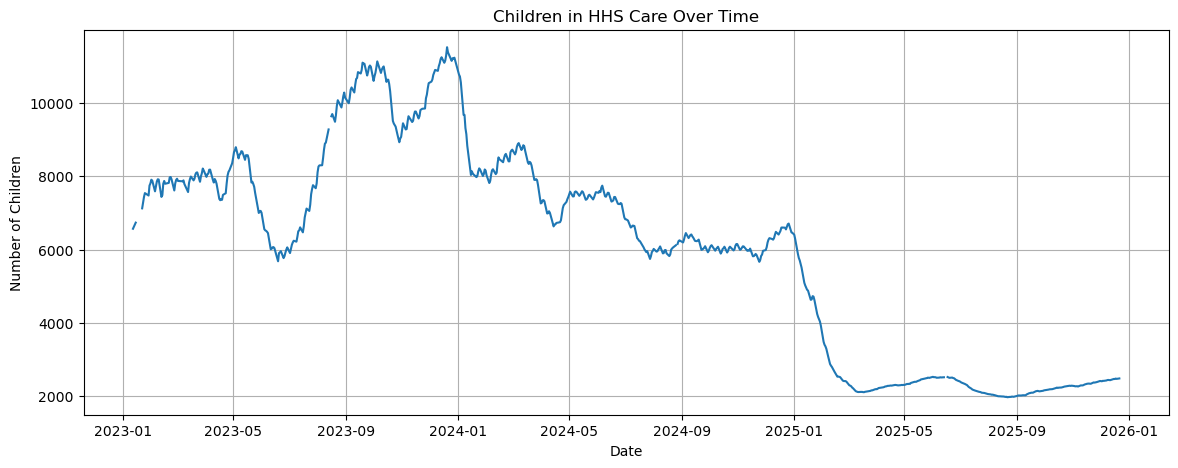

In [7]:
plt.figure(figsize=(14, 5))

plt.plot(df.index, df["hhs_care"])
plt.title("Children in HHS Care Over Time")
plt.xlabel("Date")
plt.ylabel("Number of Children")
plt.grid(True)
plt.show()

#### Transfers and discharges

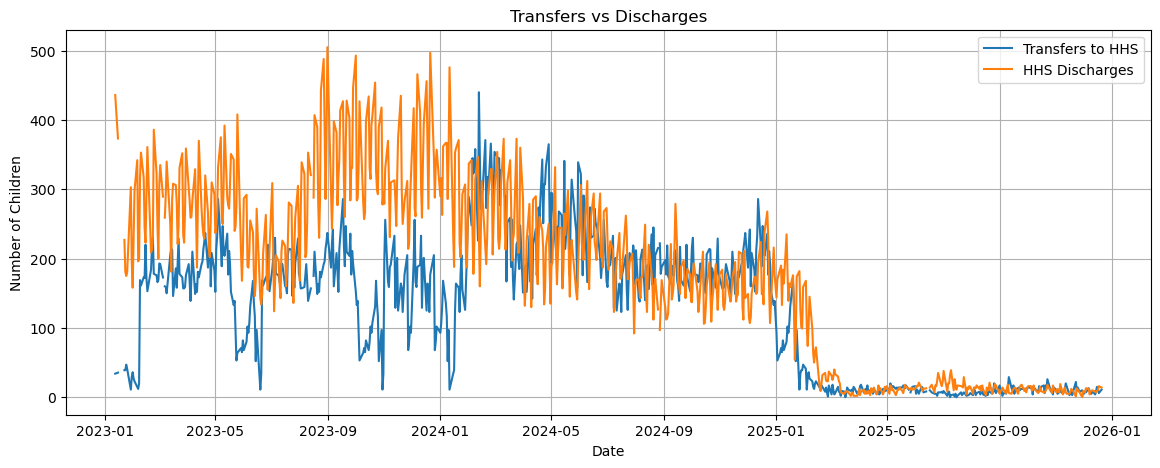

In [8]:
plt.figure(figsize=(14, 5))

plt.plot(df.index, df["transfers"], label="Transfers to HHS")
plt.plot(df.index, df["discharges"], label="HHS Discharges")

plt.title("Transfers vs Discharges")
plt.xlabel("Date")
plt.ylabel("Number of Children")
plt.legend()
plt.grid(True)
plt.show()

### Calculate net pressure

Average daily net pressure: -53.72284906422512


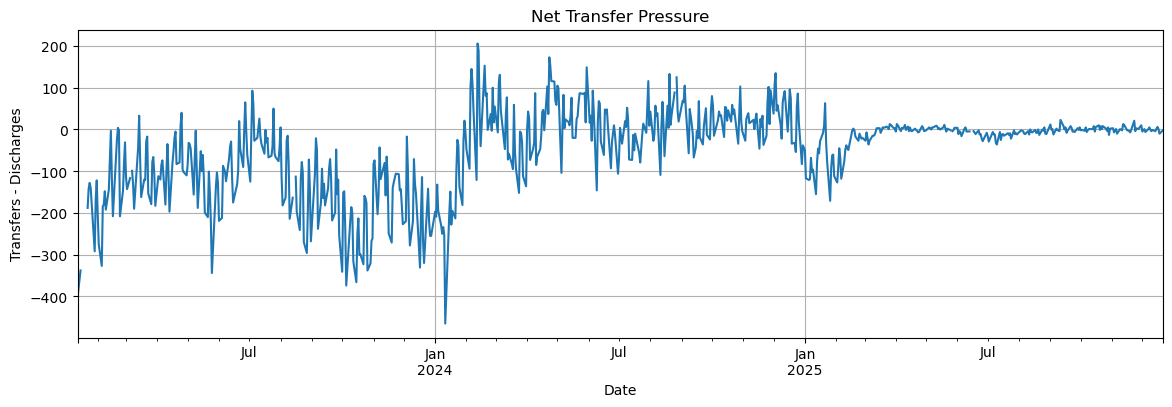

In [9]:
df["net_pressure"] = df["transfers"] - df["discharges"]

print("Average daily net pressure:", df["net_pressure"].mean())

df["net_pressure"].plot(figsize=(14, 4), title="Net Transfer Pressure")
plt.ylabel("Transfers - Discharges")
plt.grid(True)
plt.show()

### Feature engineering

In [10]:
def create_features(data, target):
    X = pd.DataFrame(index=data.index)

    X["lag_1"] = data[target].shift(1)
    X["lag_7"] = data[target].shift(7)
    X["lag_14"] = data[target].shift(14)

    X["rolling_mean_7"] = (
        data[target].shift(1).rolling(7).mean()
    )

    X["rolling_mean_14"] = (
        data[target].shift(1).rolling(14).mean()
    )

    X["rolling_std_7"] = (
        data[target].shift(1).rolling(7).std()
    )

    X["day_of_week"] = data.index.dayofweek
    X["month"] = data.index.month

    return X

print(create_features(df, "hhs_care").tail())

             lag_1        lag_7       lag_14  rolling_mean_7  rolling_mean_14  \
Date                                                                            
2025-12-17  2468.0  2439.000000  2419.000000     2453.571429      2440.785714   
2025-12-18  2481.0  2437.000000  2418.000000     2459.571429      2445.214286   
2025-12-19  2472.0  2445.333333  2421.666667     2464.571429      2449.071429   
2025-12-20  2476.0  2453.666667  2425.333333     2468.952381      2452.952381   
2025-12-21  2480.0  2462.000000  2429.000000     2472.714286      2456.857143   

            rolling_std_7  day_of_week  month  
Date                                           
2025-12-17      13.564270            2     12  
2025-12-18      15.231199            3     12  
2025-12-19      11.985662            4     12  
2025-12-20       9.019379            5     12  
2025-12-21       6.799860            6     12  


### Split the data and train forecasting models

In [11]:
def train_models(data, target):

    X = create_features(data, target)
    y = data[target]

    dataset = X.join(y.rename("target")).dropna()

    X = dataset.drop(columns="target")
    y = dataset["target"]

    if len(dataset) < 40:
        raise ValueError(
            f"Not enough valid observations for {target}."
        )

    split = int(len(dataset) * 0.8)

    X_train = X.iloc[:split]
    X_test = X.iloc[split:]

    y_train = y.iloc[:split]
    y_test = y.iloc[split:]

    models = {
        "Random Forest": RandomForestRegressor(
            n_estimators=150,
            max_depth=8,
            random_state=42
        ),

        "Gradient Boosting": GradientBoostingRegressor(
            n_estimators=100,
            random_state=42
        )
    }

    predictions = {}

    # Naive persistence baseline
    predictions["Naive Baseline"] = X_test["lag_1"].values

    for name, model in models.items():
        model.fit(X_train, y_train)
        predictions[name] = model.predict(X_test)

    results = {}

    for name, pred in predictions.items():
        mae = mean_absolute_error(y_test, pred)
        rmse = np.sqrt(mean_squared_error(y_test, pred))

        nonzero = y_test.to_numpy() != 0

        mape = (
            np.mean(
                np.abs(
                    (y_test.to_numpy()[nonzero] -
                     np.asarray(pred)[nonzero]) /
                    y_test.to_numpy()[nonzero]
                )
            ) * 100
            if nonzero.any() else np.nan
        )

        results[name] = {
            "MAE": mae,
            "RMSE": rmse,
            "MAPE (%)": mape
        }

    results_df = pd.DataFrame(results).T.sort_values("MAE")

    return models, results_df, X_test, y_test, predictions


# Train care-load models
care_models, care_results, X_test, y_test, care_predictions = (
    train_models(df, "hhs_care")
)

print("HHS CARE LOAD RESULTS")
display(care_results.round(2))

# Train discharge models
discharge_models, discharge_results, _, _, discharge_predictions = (
    train_models(df, "discharges")
)

print("DISCHARGE DEMAND RESULTS")
display(discharge_results.round(2))

HHS CARE LOAD RESULTS


,MAE,RMSE,MAPE (%)
Naive Baseline,6.70,8.25,0.30
Random Forest,55.90,75.73,2.57
Gradient Boosting,69.26,88.40,3.24


DISCHARGE DEMAND RESULTS


,MAE,RMSE,MAPE (%)
Random Forest,3.65,4.71,38.97
Naive Baseline,3.70,4.99,35.47
Gradient Boosting,4.10,5.09,53.42


### Plot actual versus predicted values

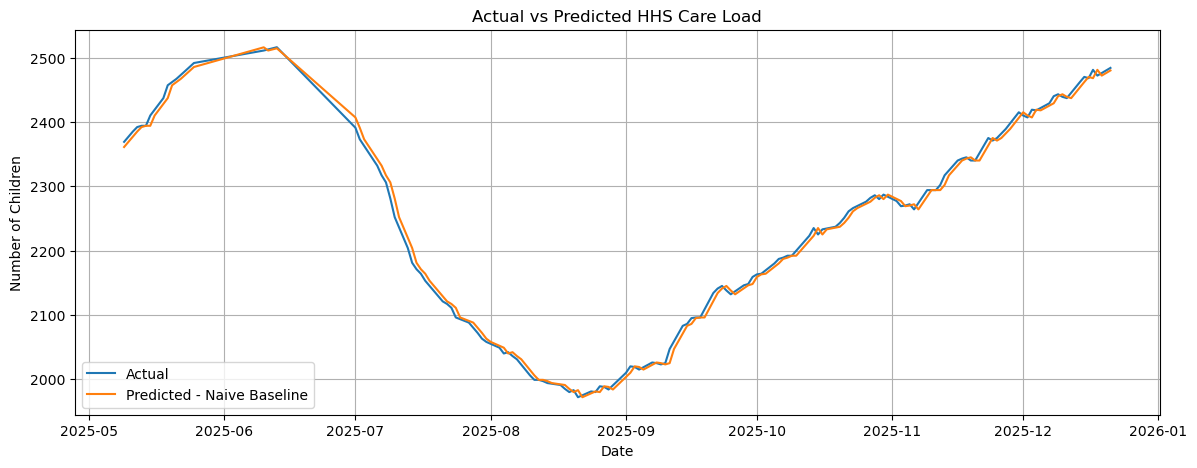

In [12]:
best_care_name = care_results["MAE"].idxmin()

plt.figure(figsize=(14, 5))

plt.plot(y_test.index, y_test, label="Actual")

plt.plot(
    y_test.index,
    care_predictions[best_care_name],
    label=f"Predicted - {best_care_name}"
)

plt.title("Actual vs Predicted HHS Care Load")
plt.xlabel("Date")
plt.ylabel("Number of Children")
plt.legend()
plt.grid(True)
plt.show()

### Forecast the next 14 days

In [18]:
# Select the best trained model (exclude Naive Baseline)
best_care_name = care_results.drop(
    index="Naive Baseline",
    errors="ignore"
)["MAE"].idxmin()

best_discharge_name = discharge_results.drop(
    index="Naive Baseline",
    errors="ignore"
)["MAE"].idxmin()

# Get trained models
best_care_model = care_models[best_care_name]
best_discharge_model = discharge_models[best_discharge_name]

# Generate 14-day forecasts
care_forecast = forecast_future(
    df, "hhs_care", best_care_model, horizon=14
)

discharge_forecast = forecast_future(
    df, "discharges", best_discharge_model, horizon=14
)

print("HHS Care Load Forecast:")
display(care_forecast)

print("Discharge Demand Forecast:")
display(discharge_forecast)

HHS Care Load Forecast:


,Forecast
2025-12-22,2371.245266
2025-12-23,2354.249316
2025-12-24,2355.834375
2025-12-25,2356.417279
2025-12-26,2354.124390
2025-12-27,2344.471430
2025-12-28,2342.600319
2025-12-29,2340.566469
2025-12-30,2340.251247
2025-12-31,2340.574803


Discharge Demand Forecast:


,Forecast
2025-12-22,12.644106
2025-12-23,12.699184
2025-12-24,11.965846
2025-12-25,11.891188
2025-12-26,11.097893
2025-12-27,9.288645
2025-12-28,8.628107
2025-12-29,12.952311
2025-12-30,12.814102
2025-12-31,11.975728


### Visualize future forecasts
#### HHS care-load forecast

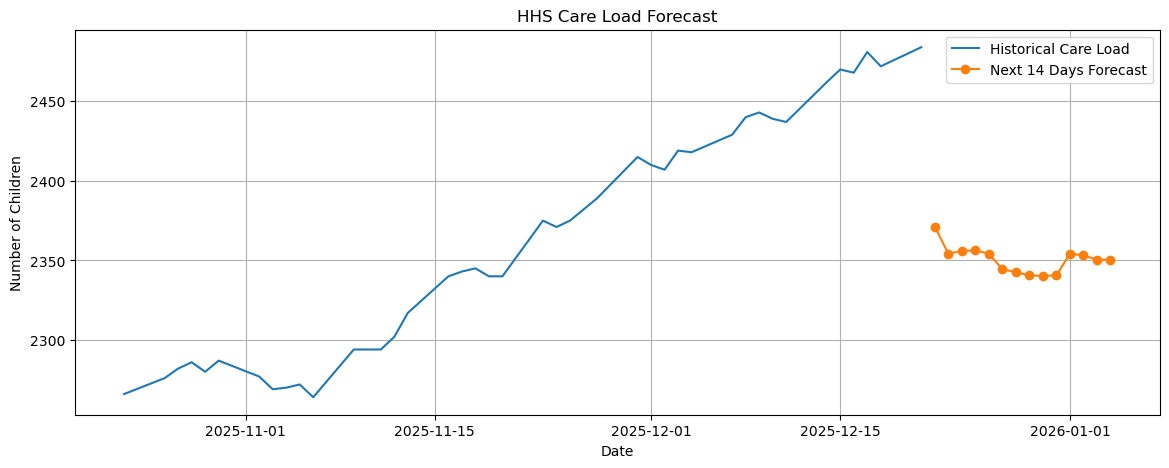

In [19]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["hhs_care"].tail(60),
    label="Historical Care Load"
)

plt.plot(
    care_forecast["Forecast"],
    marker="o",
    label="Next 14 Days Forecast"
)

plt.title("HHS Care Load Forecast")
plt.xlabel("Date")
plt.ylabel("Number of Children")
plt.legend()
plt.grid(True)
plt.show()

#### Discharge-demand forecast

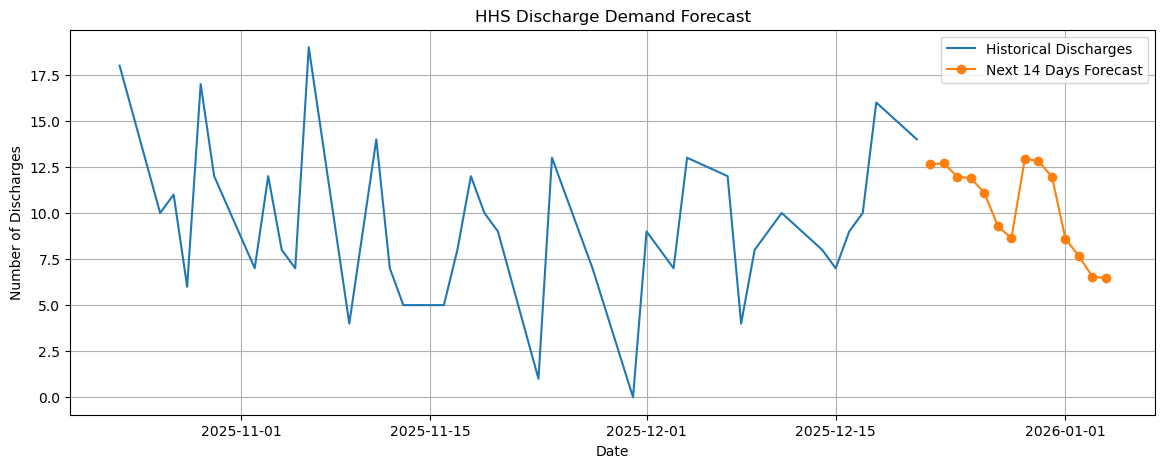

In [20]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["discharges"].tail(60),
    label="Historical Discharges"
)

plt.plot(
    discharge_forecast["Forecast"],
    marker="o",
    label="Next 14 Days Forecast"
)

plt.title("HHS Discharge Demand Forecast")
plt.xlabel("Date")
plt.ylabel("Number of Discharges")
plt.legend()
plt.grid(True)
plt.show()

### Generate a simple capacity-risk alert

In [21]:
capacity_limit = 3000  # Example only; change as appropriate

if (care_forecast["Forecast"] >= capacity_limit).any():
    print("WARNING: Potential capacity risk detected.")
else:
    print("No capacity threshold breach predicted.")

No capacity threshold breach predicted.


In [22]:
care_forecast.to_csv("HHS_Care_Load_Forecast.csv")
discharge_forecast.to_csv("HHS_Discharge_Demand_Forecast.csv")
care_results.to_csv("Care_Load_Model_Comparison.csv")
discharge_results.to_csv("Discharge_Model_Comparison.csv")

print("All forecast and evaluation files saved successfully.")

All forecast and evaluation files saved successfully.
